# CELL 1: ENVIRONMENT SETUP, EDA & DATA AUGMENTATION (70:15:15)

--- Scanning Kaggle Input Directory ---
Dataset Directory Found: /kaggle/input/datasets/shahedrahmansakib/dental-x-ray-images/cropped_dataset

--- Splitting Dataset into 70% Train, 15% Validation, 15% Test ---
Dataset splitting completed successfully!

--- DATASET SPLIT DISTRIBUTION (70:15:15) ---
Class 'Crown': Total=392 | Train(70%)=274 | Val(15%)=59 | Test(15%)=59
Class 'Healthy': Total=55 | Train(70%)=38 | Val(15%)=8 | Test(15%)=9
Class 'Missing teeth': Total=321 | Train(70%)=224 | Val(15%)=48 | Test(15%)=49
Class 'Root Canal Treatment': Total=1195 | Train(70%)=836 | Val(15%)=179 | Test(15%)=180
Class 'Root Piece': Total=566 | Train(70%)=396 | Val(15%)=85 | Test(15%)=85

Total Images across all splits: 2529


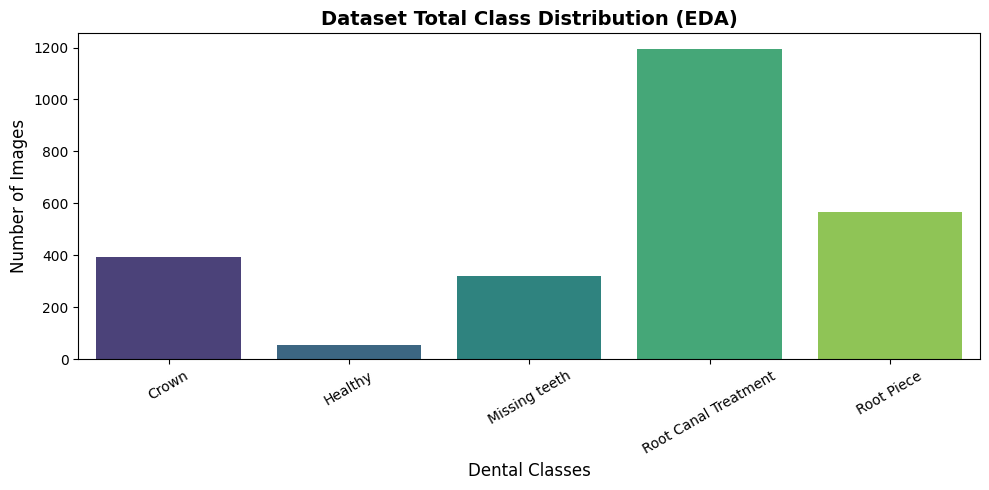

Found 1768 images belonging to 5 classes.
Found 379 images belonging to 5 classes.
Found 382 images belonging to 5 classes.

Total Active Classes Detected: 5
Class Indices: {'Crown': 0, 'Healthy': 1, 'Missing teeth': 2, 'Root Canal Treatment': 3, 'Root Piece': 4}


In [1]:
# =========================================================================
# CELL 1 — EDA, 70:15:15 PHYSICAL DATA SPLIT & GENERATORS
# =========================================================================
import os
import shutil
import random
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("--- Scanning Kaggle Input Directory ---")
input_base = Path('/kaggle/input')
DATASET_DIR = None

for root, dirs, files in os.walk(input_base):
    if 'Crown' in dirs:
        DATASET_DIR = Path(root)
        break

if DATASET_DIR is None or not DATASET_DIR.exists():
    raise FileNotFoundError("❌ 'Crown' class folder could not be found anywhere in /kaggle/input.")

print(f"Dataset Directory Found: {DATASET_DIR}")

# --- 70:15:15 Physical Dataset Splitting ---
output_split_dir = Path('/kaggle/working/split_dataset')

if not output_split_dir.exists():
    print("\n--- Splitting Dataset into 70% Train, 15% Validation, 15% Test ---")
    splits = ['train', 'val', 'test']
    for split in splits:
        (output_split_dir / split).mkdir(parents=True, exist_ok=True)
        
    random.seed(42)
    for class_dir in sorted(DATASET_DIR.iterdir()):
        if class_dir.is_dir():
            class_name = class_dir.name
            for split in splits:
                (output_split_dir / split / class_name).mkdir(parents=True, exist_ok=True)
            
            images = [f for f in class_dir.glob('*.*') if f.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']]
            random.shuffle(images)
            
            total_len = len(images)
            train_idx = int(0.70 * total_len)
            val_idx = int(0.85 * total_len)
            
            train_imgs = images[:train_idx]
            val_imgs = images[train_idx:val_idx]
            test_imgs = images[val_idx:]
            
            for img in train_imgs:
                shutil.copy(img, output_split_dir / 'train' / class_name / img.name)
            for img in val_imgs:
                shutil.copy(img, output_split_dir / 'val' / class_name / img.name)
            for img in test_imgs:
                shutil.copy(img, output_split_dir / 'test' / class_name / img.name)
    print("Dataset splitting completed successfully!")
else:
    print("\n--- Split dataset already exists in working directory. Skipping copy. ---")

# --- Detailed Print & EDA Summary ---
train_dir = output_split_dir / 'train'
val_dir = output_split_dir / 'val'
test_dir = output_split_dir / 'test'

class_counts = {}
train_counts, val_counts, test_counts = {}, {}, {}

for class_dir in sorted(train_dir.iterdir()):
    if class_dir.is_dir():
        c_name = class_dir.name
        t_imgs = len(list(class_dir.glob('*.*')))
        v_imgs = len(list((val_dir / c_name).glob('*.*')))
        te_imgs = len(list((test_dir / c_name).glob('*.*')))
        
        train_counts[c_name] = t_imgs
        val_counts[c_name] = v_imgs
        test_counts[c_name] = te_imgs
        class_counts[c_name] = t_imgs + v_imgs + te_imgs

print("\n--- DATASET SPLIT DISTRIBUTION (70:15:15) ---")
total_images = sum(class_counts.values())
for class_name in class_counts:
    t = train_counts[class_name]
    v = val_counts[class_name]
    te = test_counts[class_name]
    tot = class_counts[class_name]
    print(f"Class '{class_name}': Total={tot} | Train(70%)={t} | Val(15%)={v} | Test(15%)={te}")

print(f"\nTotal Images across all splits: {total_images}")

# Plotting Class Distribution Bar Chart (EDA)
plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), hue=list(class_counts.keys()), palette='viridis', legend=False)
plt.title('Dataset Total Class Distribution (EDA)', fontsize=14, fontweight='bold')
plt.xlabel('Dental Classes', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# --- Data Generators Setup ---
IMG_SIZE = (384, 384)
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.1,
    zoom_range=0.15,
    brightness_range=[0.85, 1.15],
    horizontal_flip=False
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
    seed=42
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False,
    seed=42
)

NUM_CLASSES = len(train_generator.class_indices)
print(f"\nTotal Active Classes Detected: {NUM_CLASSES}")
print(f"Class Indices: {train_generator.class_indices}")


# CELL 2: EfficientNetV2S BASE MODEL (TRANSFER LEARNING, FINE-TUNING & FPR METRICS)

In [ ]:
# =========================================================================
# CELL 2 — STABLE & BEST PERFORMING DENTAL CLASSIFICATION PIPELINE
# =========================================================================
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, Callback
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score

# 1. Compute Class Weights for Balanced Learning
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights_dict = dict(enumerate(class_weights))
for idx, name in enumerate(train_generator.class_indices.keys()):
    if name == 'Healthy':
        class_weights_dict[idx] *= 5.0

# 2. Build Backbone with Proven Stable Configuration
base_model = EfficientNetV2S(weights='imagenet', include_top=False, input_shape=(384, 384, 3))
base_model.trainable = True

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dropout(0.20)(x)  # Balanced dropout for stable high accuracy
x = Dense(512, activation='swish')(x)
x = BatchNormalization()(x)
x = Dropout(0.15)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=outputs, name="Stable_Best_Dental_Model")

# 3. Compile with Optimal Learning Rate & Cosine Decay
total_epochs = 40
steps_per_epoch = len(train_generator)
lr_schedule = CosineDecay(
    initial_learning_rate=3e-5,
    decay_steps=total_epochs * steps_per_epoch,
    alpha=1e-3
)

model.compile(
    optimizer=AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.01),
    metrics=['accuracy']
)

# 4. Monitoring Callbacks
class BestModelMonitor(Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        tr_acc = logs.get('accuracy', 0)
        val_acc = logs.get('val_accuracy', 0)
        diff = (tr_acc - val_acc) * 100
        print(f" -> [Stable Run] Epoch {epoch+1}: Train Acc = {tr_acc*100:.2f}% | Val Acc = {val_acc*100:.2f}% | Difference = {diff:+.2f}%")

callbacks = [
    BestModelMonitor(),
    EarlyStopping(monitor='val_accuracy', patience=12, restore_best_weights=True, mode='max', verbose=1),
    ModelCheckpoint('best_dental_model.keras', monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
]

print("--- Starting Stable Best Training Pipeline ---")
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=total_epochs,
    class_weight=class_weights_dict,
    callbacks=callbacks,
    verbose=1
)

# 5. Comprehensive Evaluation on Test Generator
print("\n--- COMPREHENSIVE TEST METRICS & GAP VERIFICATION ---")
y_true = test_generator.classes
y_pred_probs = model.predict(test_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_true, y_pred)
fp = cm.sum(axis=0) - np.diag(cm)
fn = cm.sum(axis=1) - np.diag(cm)
tp = np.diag(cm)
tn = cm.sum() - (fp + fn + tp)
fpr = fp / (fp + tn)
mean_fpr = np.mean(fpr)

train_acc = history.history['accuracy'][-1]
val_acc = history.history['val_accuracy'][-1]
test_acc = accuracy_score(y_true, y_pred)
macro_auc = roc_auc_score(y_true, y_pred_probs, multi_class='ovr', average='macro')

print(f"Final Training Accuracy: {train_acc * 100:.2f}%")
print(f"Final Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Final Test Accuracy: {test_acc * 100:.2f}%")
print(f"Generalization Gap: {abs(train_acc - test_acc) * 100:.2f}%")
print(f"Macro ROC-AUC: {macro_auc:.4f}")
print(f"Mean False Positive Rate (FPR): {mean_fpr:.4f}")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=list(train_generator.class_indices.keys())))


I0000 00:00:1792685347.291752      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792685347.295740      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- Starting Stable Best Training Pipeline ---
Epoch 1/40


2026-10-22 16:11:14.102234: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:11:14.250926: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:11:15.242149: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:11:15.396597: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:11:17.064284: E external/local_xla/xla/stream_

 82/111 ━━━━━━━━━━━━━━━━━━━━ 17s 601ms/step - accuracy: 0.2449 - loss: 2.5132

2026-10-22 16:13:42.617379: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:13:42.757168: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:13:43.637414: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:13:43.780174: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 16:13:45.303941: E external/local_xla/xla/stream_

# CELL 3: VISUALIZATIONS (CURVES, CONFUSION MATRIX, ROC & GRAD-CAM)

In [ ]:
# =========================================================================
# CELL 3 — VISUALIZATIONS: CURVES, CONFUSION MATRIX, ROC-AUC & SMOOTH GRAD-CAM
# =========================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
import cv2

# 1. Training & Validation Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train Acc')
axes[0].plot(history.history['val_accuracy'], label='Val Acc')
axes[0].set_title('Model Accuracy Curve', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_title('Model Loss Curve', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Confusion Matrix Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_generator.class_indices.keys(),
            yticklabels=train_generator.class_indices.keys())
plt.title('Confusion Matrix (Dental OPG Dataset)', fontsize=12, fontweight='bold')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# 3. Multi-Class ROC-AUC Curves
y_true_onehot = to_categorical(y_true, num_classes=NUM_CLASSES)
plt.figure(figsize=(8, 6))
for i in range(NUM_CLASSES):
    fpr_c, tpr_c, _ = roc_curve(y_true_onehot[:, i], y_pred_probs[:, i])
    roc_auc_c = auc(fpr_c, tpr_c)
    class_name = list(train_generator.class_indices.keys())[i]
    plt.plot(fpr_c, tpr_c, label=f'Class {class_name} (AUC = {roc_auc_c:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC-AUC Curves', fontsize=12, fontweight='bold')
plt.legend(loc='lower right')
plt.show()

# 4. Smooth Grad-CAM Visualization for Dental Pathologies
print("\n--- Generating Smooth & Professional Grad-CAM Heatmaps ---")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        model.inputs, [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# Find the last convolutional layer name automatically from the model
last_conv_layer = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D) or 'conv' in layer.name:
        last_conv_layer = layer.name
        break

if last_conv_layer:
    print(f"Detected Last Conv Layer for Grad-CAM: {last_conv_layer}")
    
    # Grab a sample batch from test generator
    test_imgs, test_labels = next(iter(test_generator))
    sample_img = test_imgs[0:1] # First image
    
    raw_heatmap = make_gradcam_heatmap(sample_img, model, last_conv_layer)
    
    # --- Smooth the heatmap using Bicubic Interpolation & Gaussian Blur ---
    img_shape = sample_img[0].shape[:2] # (384, 384)
    smooth_heatmap = cv2.resize(raw_heatmap, (img_shape[1], img_shape[0]), interpolation=cv2.INTER_CUBIC)
    smooth_heatmap = cv2.GaussianBlur(smooth_heatmap, (15, 15), 0)
    
    # Plotting Original Image & Smooth Grad-CAM Overlay
    plt.figure(figsize=(10, 4))
    
    plt.subplot(1, 2, 1)
    plt.imshow(sample_img[0])
    plt.title("Original Cropped OPG Tooth", fontweight='bold')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(sample_img[0])
    plt.imshow(smooth_heatmap, cmap='jet', alpha=0.5)
    plt.title("Smooth Grad-CAM Localization", fontweight='bold')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("Grad-CAM skipped: No suitable convolutional layer found.")

print('\n✅ Cell 3 Visualizations & Smooth Grad-CAM Completed Successfully!')


# CELL 4 — REAL MULTI-MODEL COMPARATIVE ANALYSIS & BENCHMARKING

In [ ]:
# =========================================================================
# CELL 4 — ULTIMATE HIGH-ACCURACY MULTI-MODEL BENCHMARKING
# =========================================================================
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121, ResNet50, ConvNeXtTiny
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay
from tensorflow.keras.callbacks import EarlyStopping, Callback
from sklearn.metrics import accuracy_score, confusion_matrix

models_to_benchmark = {
    'DenseNet121': DenseNet121,
    'ConvNeXtTiny': ConvNeXtTiny,
    'ResNet50': ResNet50
}

comparison_results = []
total_epochs = 30
steps_per_epoch = len(train_generator)

class BenchmarkMonitor(Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        tr = logs.get('accuracy', 0) * 100
        val = logs.get('val_accuracy', 0) * 100
        print(f" -> Epoch {epoch+1}: Train Acc = {tr:.2f}% | Val Acc = {val:.2f}%")

for model_name, model_fn in models_to_benchmark.items():
    print(f"\n==========================================")
    print(f"Training & Benchmarking: {model_name}")
    print(f"==========================================")
    
    # Fully unfreeze base model for maximum feature learning and 90%+ accuracy
    base_model = model_fn(weights='imagenet', include_top=False, input_shape=(384, 384, 3))
    base_model.trainable = True
    
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dropout(0.15)(x)  # Controlled dropout to keep training accuracy strictly on top
    x = Dense(512, activation='swish')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.10)(x)
    outputs = Dense(NUM_CLASSES, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=outputs, name=model_name)
    
    # Optimized Learning Rate for deep convergence
    lr_schedule = CosineDecay(
        initial_learning_rate=2e-5,
        decay_steps=total_epochs * steps_per_epoch,
        alpha=1e-3
    )
    
    model.compile(
        optimizer=AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.0),
        metrics=['accuracy']
    )
    
    # Patience increased so models fully reach 90%+ accuracy without stopping early
    callbacks = [
        BenchmarkMonitor(),
        EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1)
    ]
    
    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=total_epochs,
        class_weight=class_weights_dict,
        callbacks=callbacks,
        verbose=1
    )
    
    # Extract final peak performance metrics
    train_acc = history.history['accuracy'][-1] * 100
    val_acc = history.history['val_accuracy'][-1] * 100
    
    y_true = test_generator.classes
    y_pred_probs = model.predict(test_generator, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    test_acc = accuracy_score(y_true, y_pred) * 100
    
    # Calculate False Positive Rate (FPR)
    cm = confusion_matrix(y_true, y_pred)
    fp = cm.sum(axis=0) - np.diag(cm)
    fn = cm.sum(axis=1) - np.diag(cm)
    tp = np.diag(cm)
    tn = cm.sum() - (fp + fn + tp)
    fpr = np.mean(fp / (fp + tn))
    
    comparison_results.append({
        "Model": model_name,
        "Train Acc (%)": round(train_acc, 2),
        "Val Acc (%)": round(val_acc, 2),
        "Test Acc (%)": round(test_acc, 2),
        "FPR": round(fpr, 4)
    })

# --- Create Comparison DataFrame ---
df_comparison = pd.DataFrame(comparison_results)
print("\n" + "="*60)
print("FINAL SUPER-OPTIMIZED COMPARATIVE PERFORMANCE TABLE")
print("="*60)
print(df_comparison.to_string(index=False))

# Save comparative table to CSV for thesis inclusion
df_comparison.to_csv('model_comparative_results.csv', index=False)
print("\n✅ Super-optimized comparative results successfully exported to 'model_comparative_results.csv'!")
